# Milestone 4: Member 1 - Data Preparation

**Contributor:** Manasa

This notebook prepares the mild ColorJitter experiment proposed in Milestone 3. It reuses the baseline dataset and split manifest, verifies image integrity, and saves data-preparation artifacts for model training.

## 1. Environment and Shared Artifacts


In [1]:
import random

import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

DATA_DIR = Path("/content/malaria_data")
PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")
M4_DIR = PROJECT_DIR / "milestone4" / "data_preparation"

MANIFEST_PATH = PROJECT_DIR / "split_manifest.csv"
CONFIG_PATH = PROJECT_DIR / "data_config.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)
M4_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset folder:", DATA_DIR)
print("M4 artifacts:", M4_DIR)
print("Baseline manifest found:", MANIFEST_PATH.exists())
print("Baseline configuration found:", CONFIG_PATH.exists())

Dataset folder: /content/malaria_data
M4 artifacts: /content/drive/MyDrive/malaria_danet/milestone4/data_preparation
Baseline manifest found: True
Baseline configuration found: True


In [4]:
import json

with open(CONFIG_PATH, "r") as file:
    data_config = json.load(file)

print(json.dumps(data_config, indent=2))

{
  "dataset": "NIH/NLM Malaria Cell Images",
  "dataset_url": "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip",
  "base_paper": "DANet: A Lightweight Dilated Attention Network for Malaria Parasite Detection",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "baseline_variant": "DANet-S with LogSoftMax",
  "total_images": 27558,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "split_seed": 42,
  "split_ratios": {
    "train": 0.7,
    "validation": 0.1,
    "test": 0.2
  },
  "split_counts": {
    "train": 19290,
    "validation": 2756,
    "test": 5512
  },
  "input_size": [
    224,
    224
  ],
  "pixel_scaling": "[0, 255] to [0, 1]",
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2
  },
  "batch_size": 64,
  "unreadable_images": 0,
  "exact_duplicate_groups": 0,
  "unique_official_patient_ids": 201,
  "pati

## 2. Baseline Split Verification


In [5]:
import pandas as pd

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())
display(manifest.head())

Manifest shape: (27558, 9)
Columns: ['relative_path', 'filename', 'class_name', 'label', 'width', 'height', 'sha256', 'official_patient_id', 'split']


,relative_path,filename,class_name,label,width,height,sha256,official_patient_id,split
0,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_128.png,Uninfected,0,160,139,c8ca3d1d4a4b5fd3880b117d5157b580b4cec277d905ff...,C100P61ThinF,train
1,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_131.png,Uninfected,0,145,136,e3ae546255ee877dd6f2d3a05b70cb34d0484d79f28fef...,C100P61ThinF,test
2,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_144.png,Uninfected,0,145,142,b96da0f59af6104d38d6196f1e98560490c19fd67cf948...,C100P61ThinF,validation
3,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_21.png,Uninfected,0,100,112,9d6e182c041a37d43e997cad8b860e8ee5aedd5285e919...,C100P61ThinF,validation
4,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_25.png,Uninfected,0,124,139,ca451e7bc57abca9aa8bf280d89a1bb1ba8191c6981de7...,C100P61ThinF,test


In [6]:
split_counts = manifest["split"].value_counts()
class_counts = pd.crosstab(manifest["split"], manifest["class_name"])

assert len(manifest) == data_config["total_images"]
assert manifest["relative_path"].is_unique
assert split_counts.to_dict() == data_config["split_counts"]
assert manifest["label"].eq(
    manifest["class_name"].map(data_config["class_mapping"])
).all()

print("Baseline manifest checks passed.")

print("\nSplit counts:")
display(split_counts)

print("Class counts by split:")
display(class_counts)

Baseline manifest checks passed.

Split counts:


,count
split,
train,19290
test,5512
validation,2756


Class counts by split:


class_name,Parasitized,Uninfected
split,,
test,2756,2756
train,9645,9645
validation,1378,1378


## 3. Dataset Acquisition and Integrity Checks


In [7]:
import subprocess

ZIP_PATH = DATA_DIR / "cell_images.zip"
DATASET_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

subprocess.run(
    ["wget", "-c", "--show-progress", "-O", str(ZIP_PATH), DATASET_URL],
    check=True,
)

print(f"Downloaded file size: {ZIP_PATH.stat().st_size / 1024**2:.1f} MB")

Downloaded file size: 337.1 MB


In [8]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_DIR)

IMAGE_ROOT = DATA_DIR / "cell_images"
CLASS_NAMES = ["Uninfected", "Parasitized"]

for class_name in CLASS_NAMES:
    class_dir = IMAGE_ROOT / class_name
    assert class_dir.is_dir(), f"Missing folder: {class_dir}"
    print(f"{class_name}: {len(list(class_dir.glob('*.png'))):,} images")

Uninfected: 13,779 images
Parasitized: 13,779 images


In [9]:
image_paths = manifest["relative_path"].map(lambda path: IMAGE_ROOT / path)
missing_paths = image_paths[~image_paths.map(Path.exists)]

print("Manifest images:", len(image_paths))
print("Missing images:", len(missing_paths))

assert missing_paths.empty, "Some manifest images are missing."

print("All baseline image paths verified.")

Manifest images: 27558
Missing images: 0
All baseline image paths verified.


In [10]:
import hashlib

def file_hash(file_path):
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

current_hashes = image_paths.map(file_hash)
hash_matches = current_hashes.eq(manifest["sha256"])

print("Images checked:", len(hash_matches))
print("Hash mismatches:", (~hash_matches).sum())

assert hash_matches.all(), "Some images differ from the baseline dataset."

print("All image contents match the baseline.")

Images checked: 27558
Hash mismatches: 0
All image contents match the baseline.


## 4. Training and Evaluation Transformations


In [11]:
from torchvision import transforms

image_size = tuple(data_config["input_size"])
augmentation = data_config["training_augmentation"]

baseline_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomRotation(augmentation["rotation_degrees"]),
    transforms.RandomHorizontalFlip(
        p=augmentation["horizontal_flip_probability"]
    ),
    transforms.RandomVerticalFlip(
        p=augmentation["vertical_flip_probability"]
    ),
    transforms.ToTensor(),
])

train_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomRotation(augmentation["rotation_degrees"]),
    transforms.RandomHorizontalFlip(
        p=augmentation["horizontal_flip_probability"]
    ),
    transforms.RandomVerticalFlip(
        p=augmentation["vertical_flip_probability"]
    ),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1,
        hue=0.02,
    ),
    transforms.ToTensor(),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

print("Modified training transformations:")
print(train_transform)

print("\nEvaluation transformations:")
print(evaluation_transform)

Modified training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.2)
    RandomVerticalFlip(p=0.2)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.9, 1.1), hue=(-0.02, 0.02))
    ToTensor()
)

Evaluation transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


## 5. Augmentation Comparison


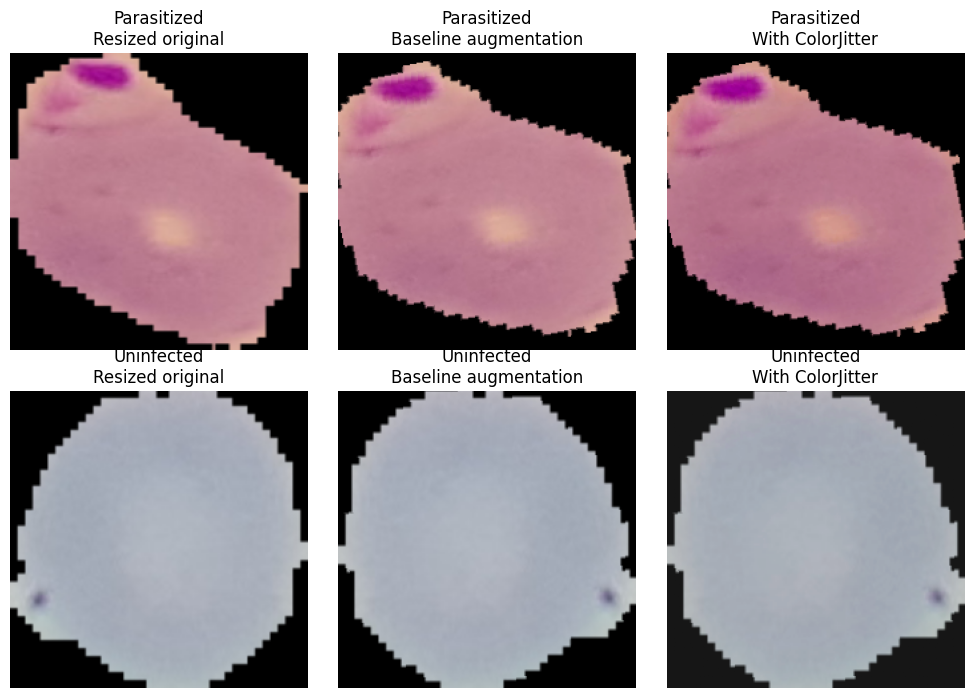

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

samples = (
    manifest[manifest["split"] == "train"]
    .groupby("class_name", group_keys=False)
    .sample(n=1, random_state=SEED)
)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for row_index, (_, row) in enumerate(samples.iterrows()):
    with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
        image = image.convert("RGB")

    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(SEED + row_index)
        baseline_image = baseline_transform(image)

        torch.manual_seed(SEED + row_index)
        modified_image = train_transform(image)

    images = [evaluation_transform(image), baseline_image, modified_image]
    titles = ["Resized original", "Baseline augmentation", "With ColorJitter"]

    for ax, tensor, title in zip(axes[row_index], images, titles):
        ax.imshow(tensor.permute(1, 2, 0).numpy())
        ax.set_title(f"{row['class_name']}\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.savefig(M4_DIR / "colorjitter_comparison.png", dpi=200)
plt.show()

## 6. Manifest Datasets and Data Loaders


In [13]:
from torch.utils.data import Dataset

class MalariaManifestDataset(Dataset):
    def __init__(self, records, image_root, transform=None):
        self.records = records.reset_index(drop=True).copy()
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]
        image_path = self.image_root / row["relative_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        return image, label

print("Manifest dataset class ready.")

Manifest dataset class ready.


In [14]:
train_dataset = MalariaManifestDataset(
    manifest[manifest["split"] == "train"],
    IMAGE_ROOT,
    transform=train_transform,
)

validation_dataset = MalariaManifestDataset(
    manifest[manifest["split"] == "validation"],
    IMAGE_ROOT,
    transform=evaluation_transform,
)

test_dataset = MalariaManifestDataset(
    manifest[manifest["split"] == "test"],
    IMAGE_ROOT,
    transform=evaluation_transform,
)

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Test images reserved for final evaluation:", len(test_dataset))

Training images: 19290
Validation images: 2756
Test images reserved for final evaluation: 5512


In [15]:
from torch.utils.data import DataLoader

batch_size = data_config["batch_size"]
train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=train_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))
print("Data-loader workers:", 0)

Training batches: 302
Validation batches: 44
Test batches: 87
Data-loader workers: 0


## 7. Training Batch Validation


In [16]:
images, labels = next(iter(train_loader))

assert images.shape == (batch_size, 3, *image_size)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert torch.isfinite(images).all()
assert images.min().item() >= 0.0
assert images.max().item() <= 1.0
assert set(labels.tolist()).issubset(data_config["class_mapping"].values())

print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Pixel range:", images.min().item(), "to", images.max().item())
print("Labels present:", sorted(labels.unique().tolist()))
print("Training batch checks passed.")

Image batch shape: (64, 3, 224, 224)
Label batch shape: (64,)
Image dtype: torch.float32
Label dtype: torch.int64
Pixel range: 0.0 to 1.0
Labels present: [0, 1]
Training batch checks passed.


## 8. M4 Configuration and Reproducibility Artifacts


In [17]:
from copy import deepcopy

m4_config = deepcopy(data_config)

m4_config["milestone"] = 4
m4_config["experiment"] = "DANet-S with mild ColorJitter"
m4_config["training_augmentation"]["color_jitter"] = {
    "brightness": 0.2,
    "contrast": 0.2,
    "saturation": 0.1,
    "hue": 0.02,
}
m4_config["data_loader_workers"] = 0
m4_config["baseline_manifest_sha256"] = file_hash(MANIFEST_PATH)
m4_config["baseline_config_sha256"] = file_hash(CONFIG_PATH)
m4_config["evaluation_preprocessing"] = [
    "Resize to 224 x 224",
    "ToTensor",
]

print(json.dumps(m4_config, indent=2))

{
  "dataset": "NIH/NLM Malaria Cell Images",
  "dataset_url": "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip",
  "base_paper": "DANet: A Lightweight Dilated Attention Network for Malaria Parasite Detection",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "baseline_variant": "DANet-S with LogSoftMax",
  "total_images": 27558,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "split_seed": 42,
  "split_ratios": {
    "train": 0.7,
    "validation": 0.1,
    "test": 0.2
  },
  "split_counts": {
    "train": 19290,
    "validation": 2756,
    "test": 5512
  },
  "input_size": [
    224,
    224
  ],
  "pixel_scaling": "[0, 255] to [0, 1]",
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2,
    "color_jitter": {
      "brightness": 0.2,
      "contrast": 0.2,
      "saturation": 0.1,
      "hue": 0.02
    }
  },
  

In [18]:
import shutil

M4_CONFIG_PATH = M4_DIR / "data_config.json"
M4_MANIFEST_PATH = M4_DIR / "split_manifest.csv"

with open(M4_CONFIG_PATH, "w") as file:
    json.dump(m4_config, file, indent=2)

shutil.copy2(MANIFEST_PATH, M4_MANIFEST_PATH)

assert file_hash(M4_MANIFEST_PATH) == m4_config["baseline_manifest_sha256"]

print("M4 configuration saved:", M4_CONFIG_PATH)
print("M4 manifest saved:", M4_MANIFEST_PATH)
print("Saved manifest matches the baseline exactly.")

M4 configuration saved: /content/drive/MyDrive/malaria_danet/milestone4/data_preparation/data_config.json
M4 manifest saved: /content/drive/MyDrive/malaria_danet/milestone4/data_preparation/split_manifest.csv
Saved manifest matches the baseline exactly.


In [19]:
import platform

import PIL
import torchvision

environment = {
    "python": platform.python_version(),
    "pytorch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
}

with open(M4_DIR / "environment.json", "w") as file:
    json.dump(environment, file, indent=2)

print(json.dumps(environment, indent=2))

{
  "python": "3.13.16",
  "pytorch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "cuda": "13.0",
  "cudnn": 92700,
  "gpu": "Tesla T4"
}


## 9. Preparation Summary and Artifact Checksums


In [20]:
summary = f"""# Milestone 4: Data Preparation Summary

## Experiment
DANet-S with mild ColorJitter added only to training images.

## Dataset verification
- Images checked: {len(manifest):,}
- Missing images: {len(missing_paths)}
- SHA-256 mismatches against baseline: {int((~hash_matches).sum())}
- Split manifest: exact copy of the baseline manifest
- Class mapping: Uninfected = 0, Parasitized = 1

## Shared settings
- Training images: {len(train_dataset):,}
- Validation images: {len(validation_dataset):,}
- Reserved test images: {len(test_dataset):,}
- Input size: {image_size}
- Batch size: {batch_size}
- Data-loader workers: 0
- Random seed: {SEED}

## Training augmentation
Resize, rotation within 15 degrees, horizontal flip (0.2),
vertical flip (0.2), ColorJitter, and tensor conversion.

ColorJitter: brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02.

## Evaluation preprocessing
Resize and tensor conversion only. No ColorJitter.

## Training handoff
Reconstruct transforms using the saved configuration, including ColorJitter.
Reset random seeds and recreate data loaders before training:
the batch check has advanced the current random states.

## Limitations
The baseline image-level split retains patient overlap across partitions.
This notebook verifies data preparation; it does not establish improvement.
"""

SUMMARY_PATH = M4_DIR / "data_preparation_summary.md"
SUMMARY_PATH.write_text(summary, encoding="utf-8")

print(summary)
print("Summary saved:", SUMMARY_PATH)

# Milestone 4: Data Preparation Summary

## Experiment
DANet-S with mild ColorJitter added only to training images.

## Dataset verification
- Images checked: 27,558
- Missing images: 0
- SHA-256 mismatches against baseline: 0
- Split manifest: exact copy of the baseline manifest
- Class mapping: Uninfected = 0, Parasitized = 1

## Shared settings
- Training images: 19,290
- Validation images: 2,756
- Reserved test images: 5,512
- Input size: (224, 224)
- Batch size: 64
- Data-loader workers: 0
- Random seed: 42

## Training augmentation
Resize, rotation within 15 degrees, horizontal flip (0.2),
vertical flip (0.2), ColorJitter, and tensor conversion.

ColorJitter: brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02.

## Evaluation preprocessing
Resize and tensor conversion only. No ColorJitter.

## Training handoff
Reconstruct transforms using the saved configuration, including ColorJitter.
Reset random seeds and recreate data loaders before training:
the batch check has advanced t

In [21]:
artifact_names = [
    "data_config.json",
    "split_manifest.csv",
    "colorjitter_comparison.png",
    "environment.json",
    "data_preparation_summary.md",
]

artifacts = []

for name in artifact_names:
    path = M4_DIR / name
    assert path.is_file(), f"Missing artifact: {path}"

    artifacts.append({
        "filename": name,
        "size_bytes": path.stat().st_size,
        "sha256": file_hash(path),
    })

with open(M4_DIR / "data_artifact_manifest.json", "w") as file:
    json.dump(artifacts, file, indent=2)

display(pd.DataFrame(artifacts))
print("Data-preparation artifacts verified and recorded.")

,filename,size_bytes,sha256
0,data_config.json,1632,b3ff62fedd3b582dce272a4034dfbdfec77c902996021c...
1,split_manifest.csv,5747265,aea08bdec4626ae188204039369aafe14b3a9ac9ce0782...
2,colorjitter_comparison.png,720294,d721a1fc45b3c039c219c6af37c2bb5c6936bc2799a689...
3,environment.json,207,c9ad9b4e0fc4647aa5580a90b1e2c5977fffe577a86f3c...
4,data_preparation_summary.md,1192,f483e3942a81dcf50578e4d993d607b3c60e588aa5b83b...


Data-preparation artifacts verified and recorded.
